In [41]:
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
string_file = 'string.txt'

string_df = pd.read_csv(
    string_file,
    sep=r"\s+"
)
print("Shape:", string_df.shape)
string_df.head()

string_df.to_csv('string.csv', sep=',', index=False)

string_df.head()



Shape: (93708, 10)


,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338


In [25]:
# 1. Filter STRING interactions using medium-confidence cutoff
string_filtered = string_df[
    string_df["combined_score"] >= 400
].copy()

# 2. Calculate degree for each protein
degree_df = (
    string_filtered
    .groupby("protein1")["protein2"]
    .nunique()
    .reset_index(name="degree")
    .rename(columns={"protein1": "protein_id"})
)

# 3. Check the result
degree_df.head()

,protein_id,degree
0,511145.b0002,4
1,511145.b0008,3
2,511145.b0009,4
3,511145.b0014,26
4,511145.b0015,29


In [26]:
expression_file = 'precise_mg1655_expression.csv'
expression_df = pd.read_csv(expression_file)

print(expression_df.shape)
expression_df.head()

(4305, 587)


,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430


In [27]:
# Convert STRING protein ID to E. coli locus tag
degree_df["gene_id"] = (
    degree_df["protein_id"]
    .str.replace("511145.", "", regex=False)
)

degree_df.head()

,protein_id,degree,gene_id
0,511145.b0002,4,b0002
1,511145.b0008,3,b0008
2,511145.b0009,4,b0009
3,511145.b0014,26,b0014
4,511145.b0015,29,b0015


In [28]:
# Merge protein degree with gene expression data
degree_expression_df = pd.merge(
    degree_df,
    expression_df,
    on="gene_id",
    how="inner"
)

print(degree_expression_df.shape)
degree_expression_df.head()

(2251, 589)


,protein_id,degree,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,511145.b0002,4,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
1,511145.b0008,3,b0008,-0.142828,-0.652939,1.365931,0.635379,0.603098,1.111408,1.018034,...,0.112757,0.266787,0.186043,-0.297909,-0.259931,0.948028,1.036374,0.993569,1.049810,1.447697
2,511145.b0009,4,b0009,-0.142569,-1.392046,1.201413,1.163233,1.136169,1.284574,1.392161,...,-0.681286,0.048930,-0.518525,0.241266,-0.059813,1.183566,1.097356,0.977128,1.603740,1.037476
3,511145.b0014,26,b0014,-0.225867,-0.381914,-1.741237,0.828475,0.847240,-0.612834,-0.682152,...,-0.905977,0.604662,0.529396,0.309448,-0.247685,-0.510368,-0.607535,-0.021575,0.043524,-1.634491
4,511145.b0015,29,b0015,-0.155054,-0.998241,-0.961966,1.158422,1.227208,0.674104,0.584749,...,-0.805394,0.729521,0.646539,0.377724,-0.127264,-0.360727,-0.288270,0.638324,0.681661,-0.988455


In [29]:
# Convert STRING protein IDs to E. coli locus tags
string_filtered["gene1"] = (
    string_filtered["protein1"]
    .str.replace("511145.", "", regex=False)
)

string_filtered["gene2"] = (
    string_filtered["protein2"]
    .str.replace("511145.", "", regex=False)
)

string_filtered[
    ["gene1", "gene2", "combined_score"]
].head()


,gene1,gene2,combined_score
0,b0002,b0436,456
2,b0002,b1945,775
6,b0002,b3940,988
7,b0002,b4024,900
29,b0008,b2464,900


In [30]:
# Keep only one direction for each interaction pair
interaction_df = (
    string_filtered[
        ["gene1", "gene2", "combined_score"]
    ]
    .drop_duplicates(
        subset=["gene1", "gene2"]
    )
)

# Since STRING contains both A-B and B-A,
# keep each undirected pair only once
interaction_df["pair"] = interaction_df.apply(
    lambda row: tuple(sorted([row["gene1"], row["gene2"]])),
    axis=1
)

interaction_df = (
    interaction_df
    .drop_duplicates(subset="pair")
    .drop(columns="pair")
    .reset_index(drop=True)
)

print(interaction_df.shape)

(28684, 3)


In [31]:
# Set gene_id as index for easy expression lookup
expression_matrix = expression_df.set_index("gene_id")

expression_matrix.shape

(4305, 586)

In [32]:
# Calculate expression correlation for each interaction pair (covariance)
interaction_df["expression_correlation"] = interaction_df.apply(
    lambda row: expression_matrix.loc[row["gene1"]].corr(
        expression_matrix.loc[row["gene2"]]
    ),
    axis=1
)

interaction_df.head()

,gene1,gene2,combined_score,expression_correlation
0,b0002,b0436,456,0.395852
1,b0002,b1945,775,0.052565
2,b0002,b3940,988,0.413680
3,b0002,b4024,900,0.680709
4,b0008,b2464,900,0.205923


In [33]:
expression_matrix = expression_df.set_index("gene_id")
expression_matrix.shape

(4305, 586)

In [34]:
# Calculate expression correlation for each interaction pair
interaction_df["expression_correlation"] = interaction_df.apply(
    lambda row: expression_matrix.loc[row["gene1"]].corr(
        expression_matrix.loc[row["gene2"]]
    ),
    axis=1
)

interaction_df.head()

,gene1,gene2,combined_score,expression_correlation
0,b0002,b0436,456,0.395852
1,b0002,b1945,775,0.052565
2,b0002,b3940,988,0.413680
3,b0002,b4024,900,0.680709
4,b0008,b2464,900,0.205923


In [35]:
# Create a protein-centered table:
# each interaction contributes once to each protein

corr_gene1 = interaction_df[
    ["gene1", "gene2", "expression_correlation"]
].rename(
    columns={
        "gene1": "gene_id",
        "gene2": "partner_id"
    }
)

corr_gene2 = interaction_df[
    ["gene2", "gene1", "expression_correlation"]
].rename(
    columns={
        "gene2": "gene_id",
        "gene1": "partner_id"
    }
)

partner_corr_df = pd.concat(
    [corr_gene1, corr_gene2],
    ignore_index=True
)

print(partner_corr_df.shape)
partner_corr_df.head(10)

(57368, 3)


,gene_id,partner_id,expression_correlation
0,b0002,b0436,0.395852
1,b0002,b1945,0.052565
2,b0002,b3940,0.413680
3,b0002,b4024,0.680709
4,b0008,b2464,0.205923
5,b0008,b2465,0.228100
6,b0008,b3781,0.678435
7,b0009,b0782,-0.050359
8,b0009,b0827,0.505975
9,b0009,b1727,0.263971


In [36]:
# Calculate mean expression correlation with partners for each gene
mean_corr_df = (
    partner_corr_df
    .groupby("gene_id")["expression_correlation"]
    .mean()
    .reset_index(name="mean_partner_correlation")
)

print(mean_corr_df.shape)
mean_corr_df.head()

(2251, 2)


,gene_id,mean_partner_correlation
0,b0002,0.385701
1,b0008,0.370819
2,b0009,0.273925
3,b0014,0.208064
4,b0015,0.148163


In [37]:
protein_summary_df = pd.merge(
    degree_df,
    mean_corr_df,
    on="gene_id",
    how="inner"
)

print(protein_summary_df.shape)
protein_summary_df.head()

(2251, 4)


,protein_id,degree,gene_id,mean_partner_correlation
0,511145.b0002,4,b0002,0.385701
1,511145.b0008,3,b0008,0.370819
2,511145.b0009,4,b0009,0.273925
3,511145.b0014,26,b0014,0.208064
4,511145.b0015,29,b0015,0.148163


In [38]:
# Second hypothesis: 'hub geen expression changes' 
# correlates with 'sum of partners' expression changes'
# select 1 protein as an example, whose degree is 50-100 
candidate_hubs = (
    protein_summary_df[
        protein_summary_df["degree"].between(50, 100)
    ]
    .sort_values("degree", ascending=False)
)

candidate_hubs[
    ["gene_id", "degree", "mean_partner_correlation"]
].head(10)

,gene_id,degree,mean_partner_correlation
2015,b3985,100,0.581733
212,b0436,100,0.519588
576,b1094,99,0.016316
1862,b3649,99,0.135514
2018,b3988,98,0.347624
1699,b3340,90,0.596848
472,b0911,82,0.577692
1921,b3781,81,0.132523
2016,b3986,80,0.626824
703,b1378,75,0.109406


In [39]:
candidate_hubs = (
    protein_summary_df[
        protein_summary_df["degree"].between(50, 100)
    ]
    .sort_values("degree", ascending=False)
)

candidate_hubs[
    ["gene_id", "degree", "mean_partner_correlation"]
].head(10)

,gene_id,degree,mean_partner_correlation
2015,b3985,100,0.581733
212,b0436,100,0.519588
576,b1094,99,0.016316
1862,b3649,99,0.135514
2018,b3988,98,0.347624
1699,b3340,90,0.596848
472,b0911,82,0.577692
1921,b3781,81,0.132523
2016,b3986,80,0.626824
703,b1378,75,0.109406



 Hub: b3985

 Number of partners: 100


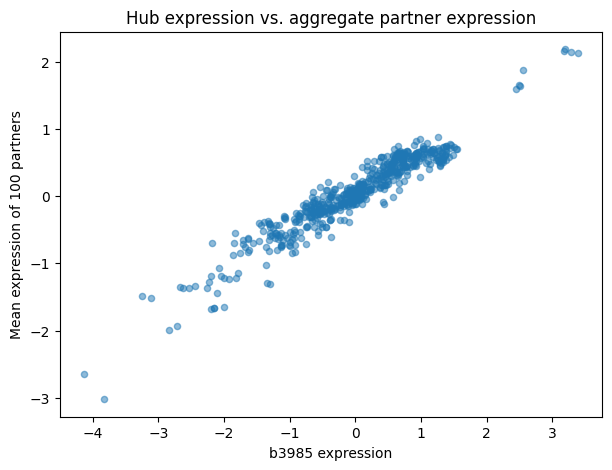


 Hub: b0436

 Number of partners: 100


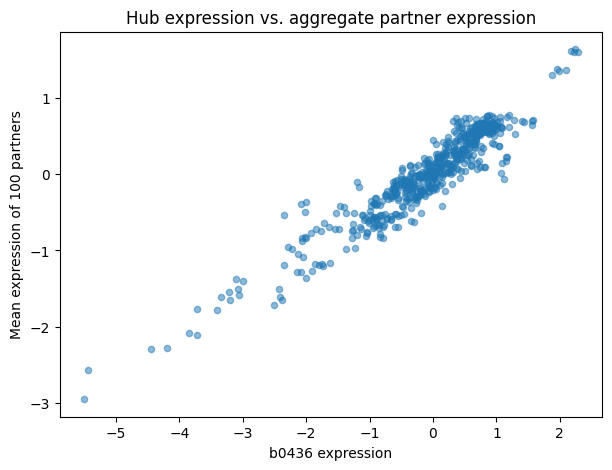


 Hub: b1094

 Number of partners: 99


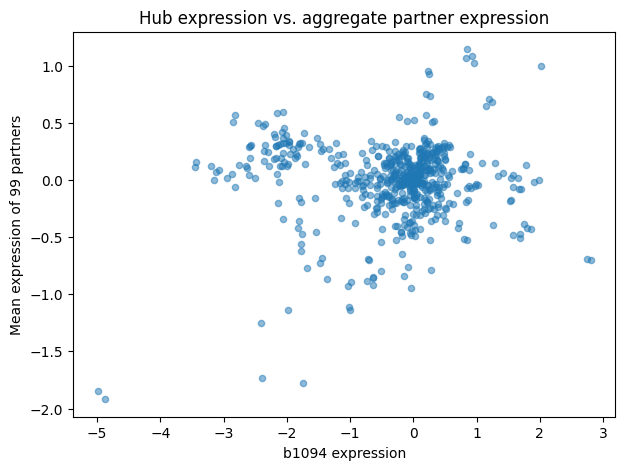


 Hub: b3649

 Number of partners: 99


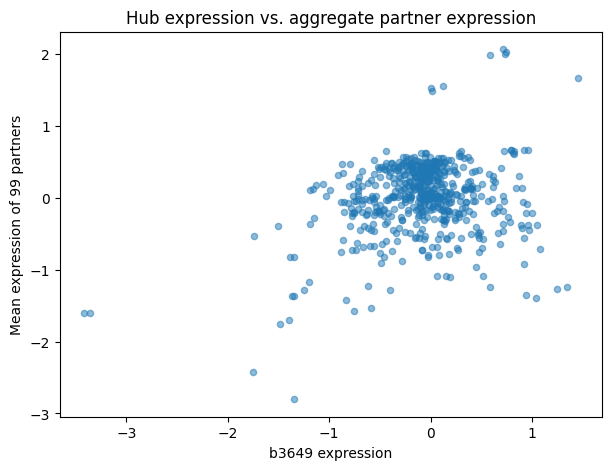


 Hub: b3988

 Number of partners: 98


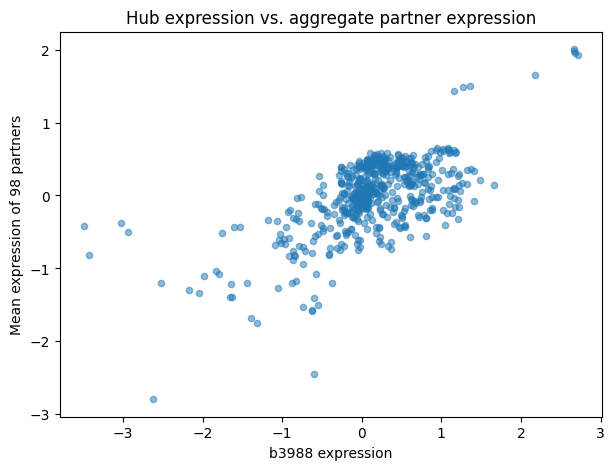


 Hub: b3340

 Number of partners: 90


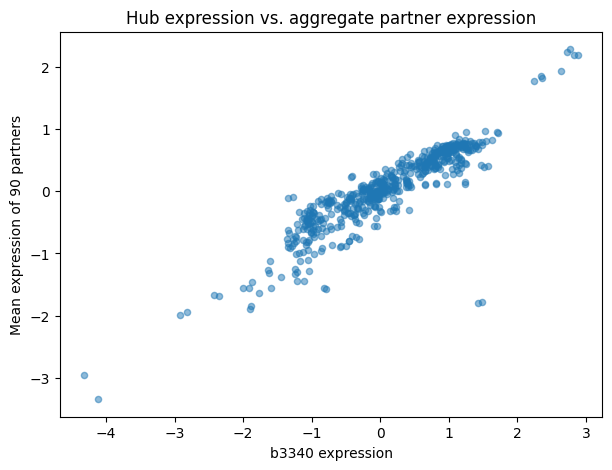


 Hub: b0911

 Number of partners: 82


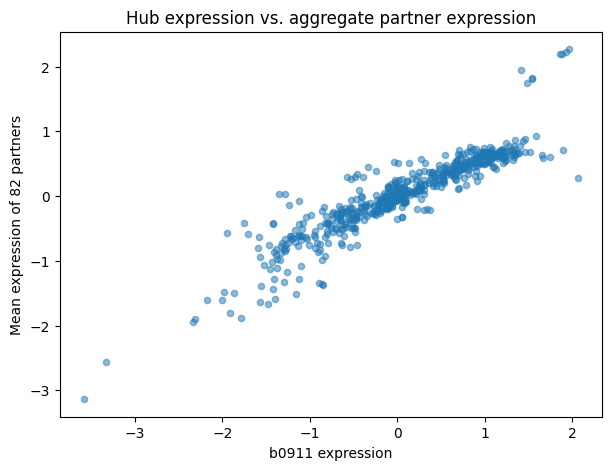


 Hub: b3781

 Number of partners: 81


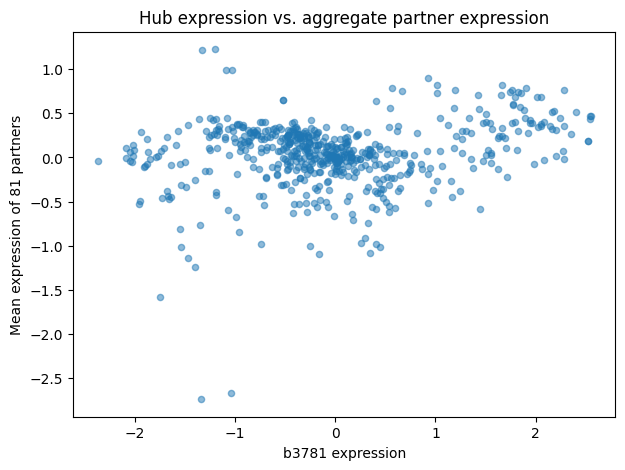


 Hub: b3986

 Number of partners: 80


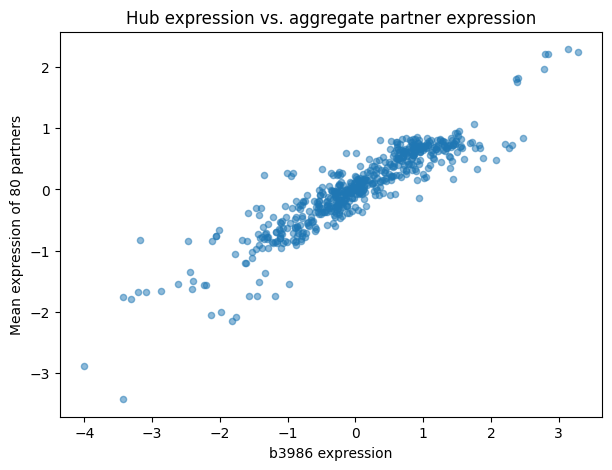


 Hub: b1378

 Number of partners: 75


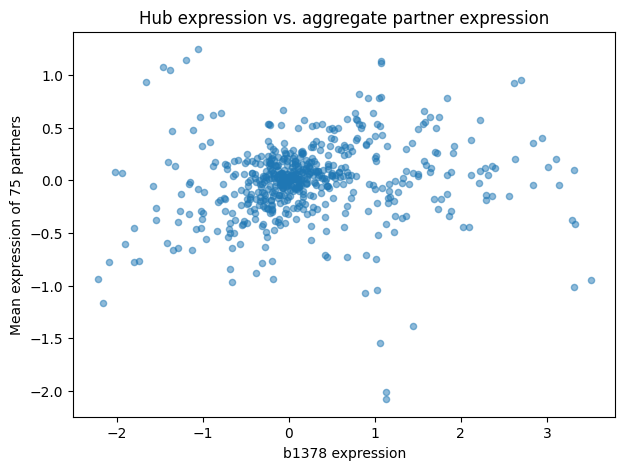


 Hub: b3169

 Number of partners: 70


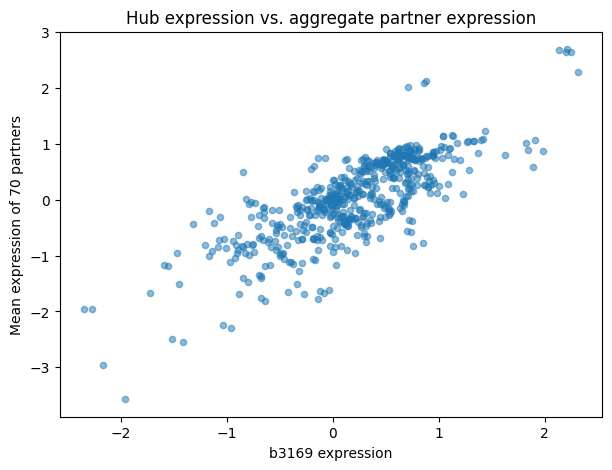


 Hub: b3982

 Number of partners: 69


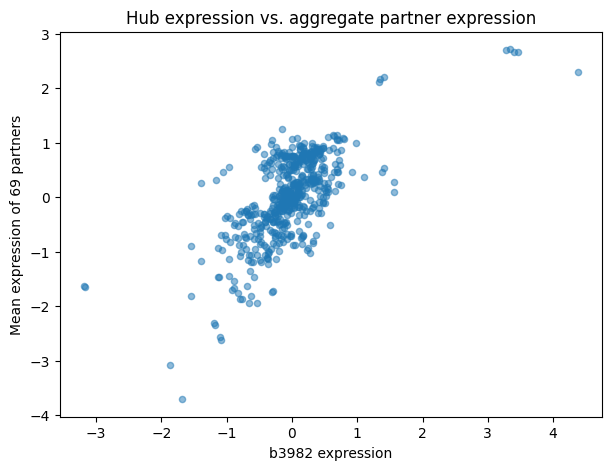


 Hub: b4506

 Number of partners: 68


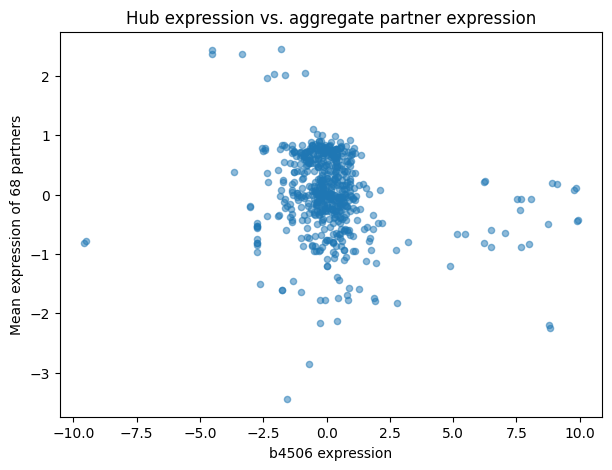


 Hub: b0093

 Number of partners: 68


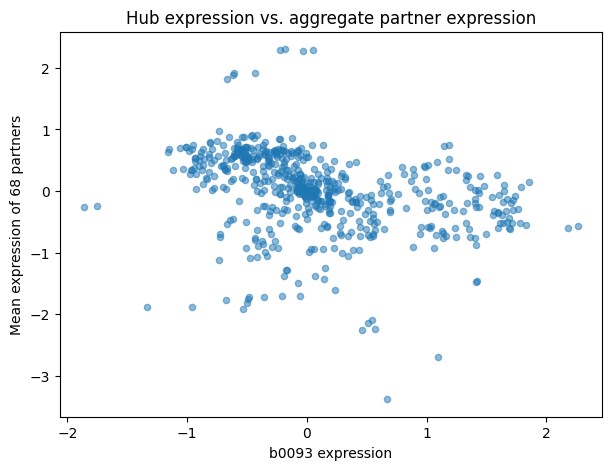


 Hub: b1413

 Number of partners: 67


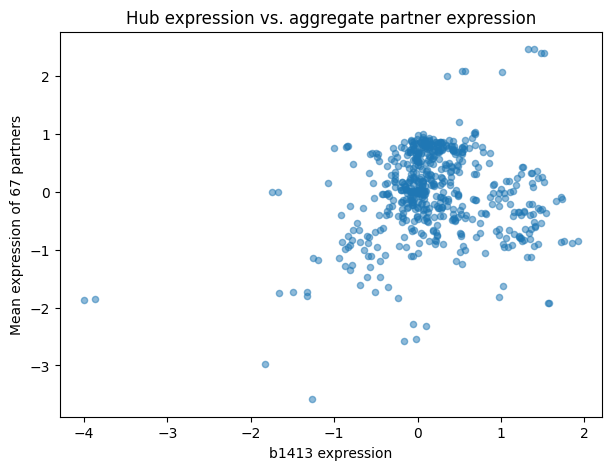


 Hub: b3300

 Number of partners: 67


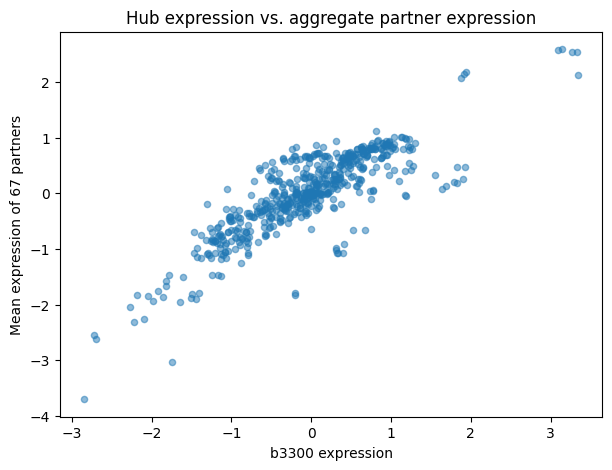


 Hub: b3981

 Number of partners: 64


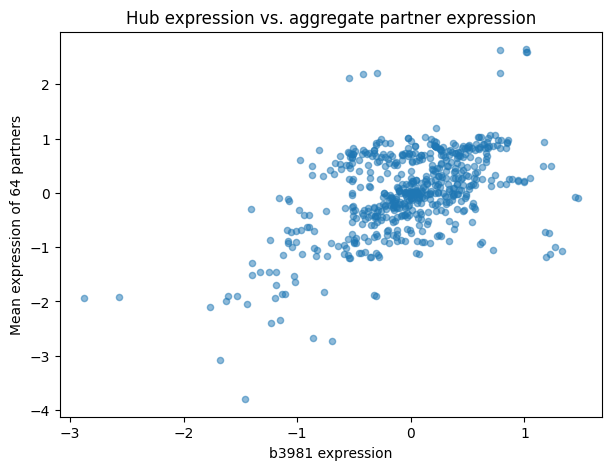


 Hub: b0296

 Number of partners: 64


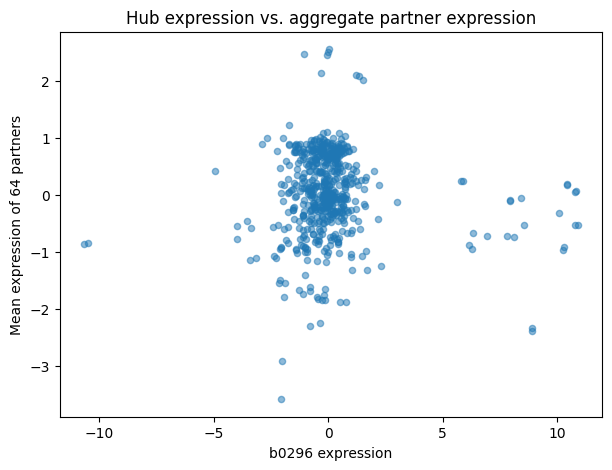


 Hub: b2610

 Number of partners: 63


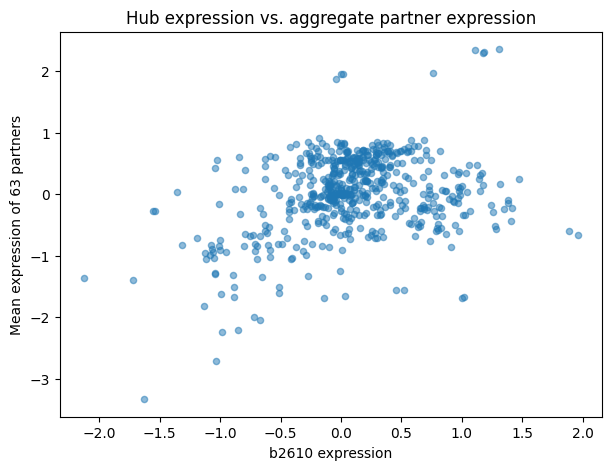


 Hub: b3705

 Number of partners: 63


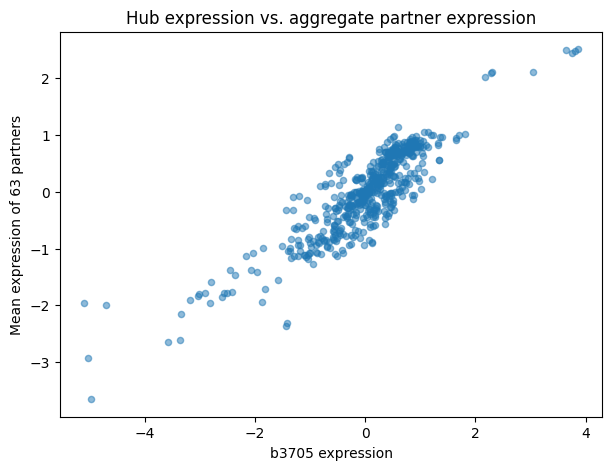


 Hub: b3175

 Number of partners: 62


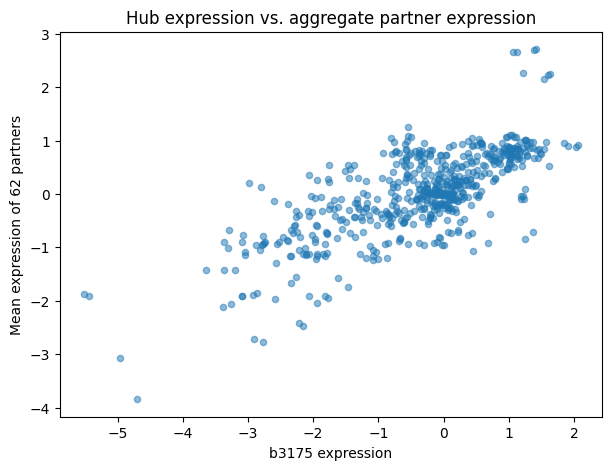


 Hub: b3980

 Number of partners: 61


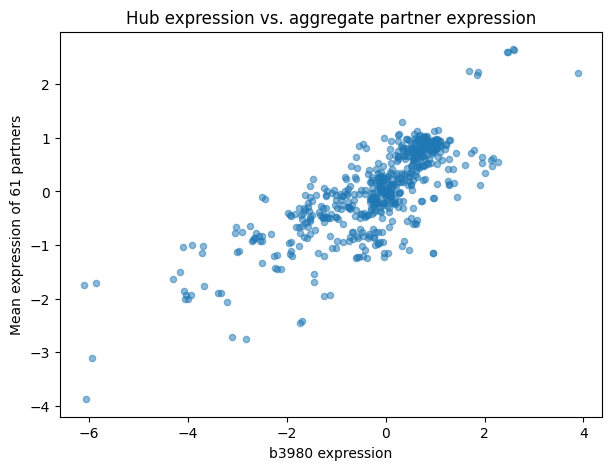


 Hub: b3339

 Number of partners: 60


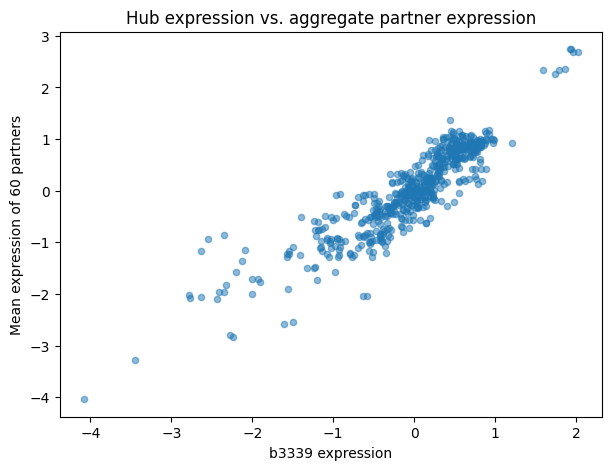


 Hub: b2891

 Number of partners: 60


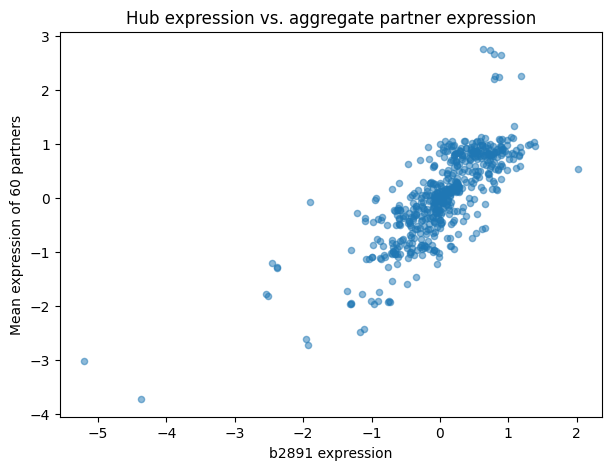


 Hub: b3168

 Number of partners: 60


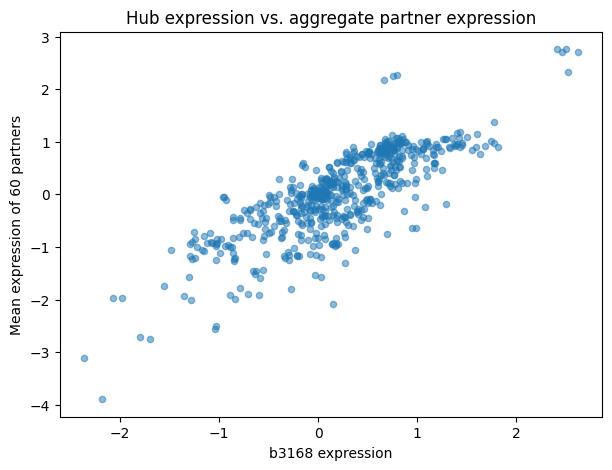


 Hub: b2597

 Number of partners: 59


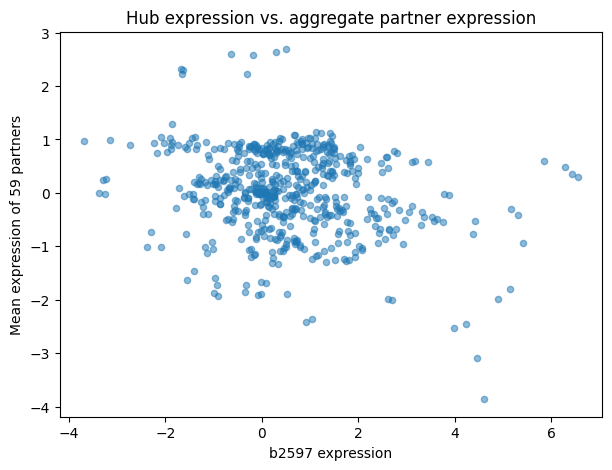


 Hub: b0424

 Number of partners: 59


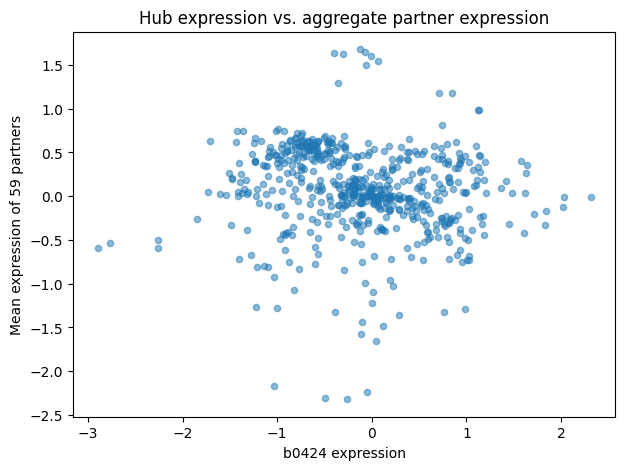


 Hub: b0172

 Number of partners: 58


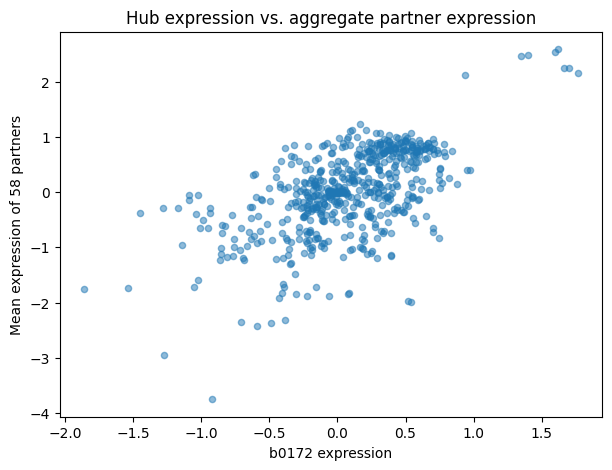


 Hub: b3842

 Number of partners: 58


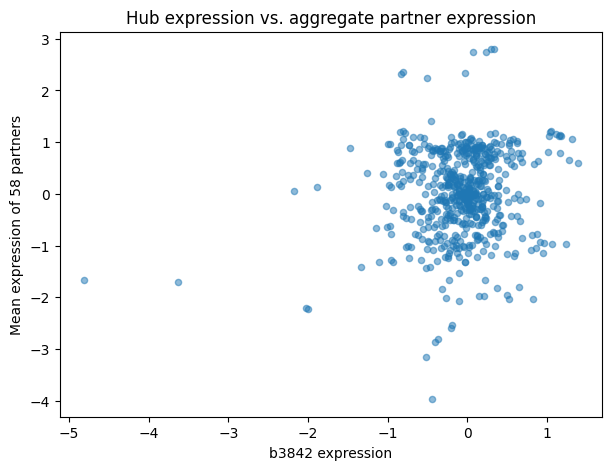


 Hub: b2620

 Number of partners: 58


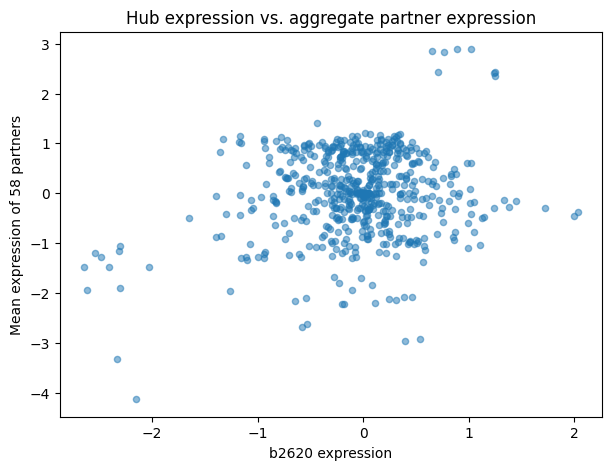


 Hub: b3590

 Number of partners: 58


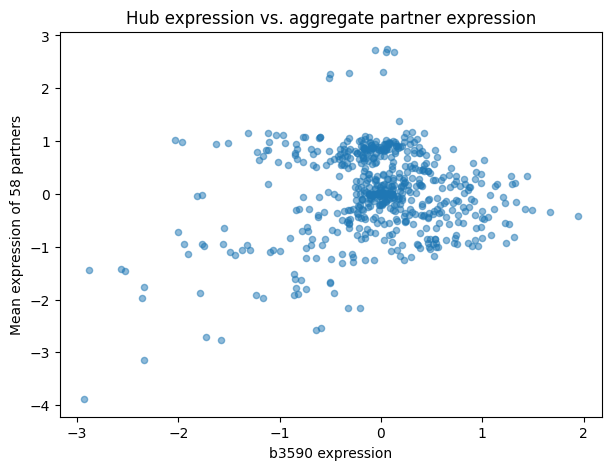


 Hub: b3203

 Number of partners: 58


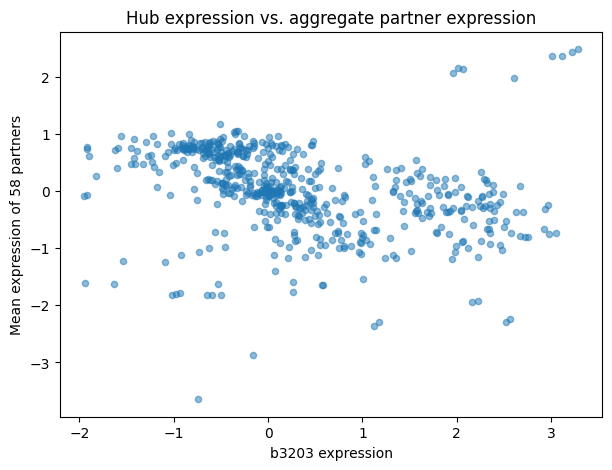


 Hub: b4375

 Number of partners: 57


In [ ]:
#all the hub expressions
total_hub_expression = []
total_partner_mean = []

for hub_gene in candidate_hubs["gene_id"]:
    hub_partners = partner_corr_df.loc[
    partner_corr_df["gene_id"] == hub_gene,
    "partner_id"
    ].tolist()

    print("\n Hub:", hub_gene)
    print("\n Number of partners:", len(hub_partners))

    #expression response of the hub
    hub_expression = expression_matrix.loc[hub_gene]

    #expression responses of its 100 partners
    partner_expression = expression_matrix.loc[hub_partners]

    #sum and mean of partner expression responses in each sample
    partner_sum = partner_expression.sum(axis=0)
    partner_mean = partner_expression.mean(axis=0)

    #combine them into one table
    hub_partner_profile = pd.DataFrame({
        "hub_expression": hub_expression,
        "partner_sum": partner_sum,
        "partner_mean": partner_mean
    })

    total_hub_expression.append(hub_expression)
    total_partner_mean.append(partner_mean)

    hub_partner_profile.head(10)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        hub_partner_profile["hub_expression"],
        hub_partner_profile["partner_mean"],
        alpha=0.5,
        s=20
    )

    plt.xlabel(f"{hub_gene} expression")
    plt.ylabel(f"Mean expression of {len(hub_partners)} partners")
    plt.title("Hub expression vs. aggregate partner expression")

    plt.savefig(f"hub_{hub_gene}_expression_correlation.png", dpi=300)
    plt.show()